In [2]:
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import silhouette_score

In [6]:
df = pd.read_csv('Mall.csv')
print(df.head())

   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [7]:
print(df.isnull().sum())
print(df.duplicated().sum())

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64
0


In [8]:
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]

In [9]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

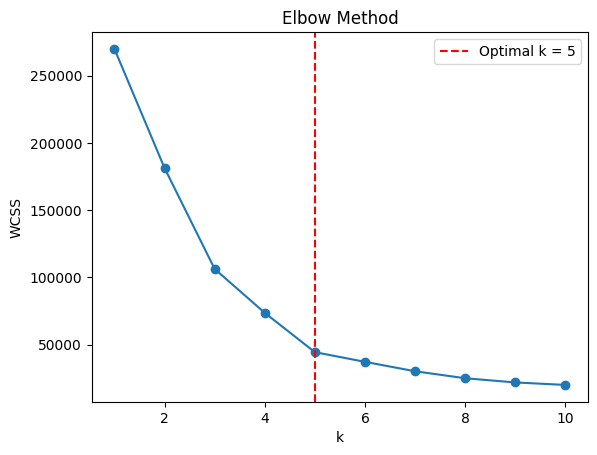

In [10]:
plt.plot(range(1, 11), wcss, marker='o')
plt.axvline(5, color='r', linestyle='--', label='Optimal k = 5')
plt.legend(); plt.title("Elbow Method"); plt.xlabel("k"); plt.ylabel("WCSS"); plt.show()

In [12]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

kmeans.fit(X)

clusters = kmeans.predict(X)

print(clusters)

[4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4 2 4
 2 4 2 4 2 4 0 4 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 1 3 1 0 1 3 1 3 1 0 1 3 1 3 1 3 1 3 1 0 1 3 1 3 1
 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1 3
 1 3 1 3 1 3 1 3 1 3 1 3 1 3 1]


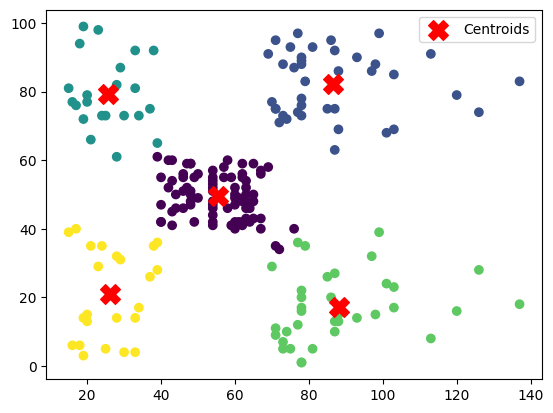

In [13]:
plt.scatter(X.iloc[:,0], X.iloc[:,1], c=clusters, cmap='viridis')
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1],
            c='red', marker='X', s=200, label='Centroids')
plt.legend(); plt.show()

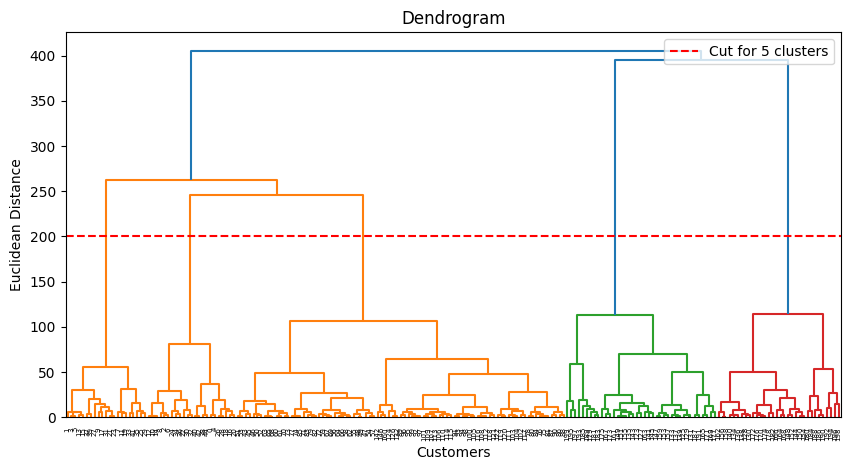

In [28]:
plt.figure(figsize=(10, 5))
dendrogram(linkage(X, method='ward'))
plt.axhline(y=200, color='r', linestyle='--', label='Cut for 5 clusters')
plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")
plt.legend()
plt.show()

In [17]:
hc = AgglomerativeClustering(n_clusters=5)

hc_clusters = hc.fit_predict(X)

print(hc_clusters)

[4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4 3 4
 3 4 3 4 3 4 1 4 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 2 1 2 1 2 0 2 0 2 1 2 0 2 0 2 0 2 0 2 1 2 0 2 1 2
 0 2 0 2 0 2 0 2 0 2 0 2 1 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0
 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2]


In [18]:
print("K-Means silhouette:", silhouette_score(X, clusters))
print("Hierarchical silhouette:", silhouette_score(X, hc_clusters))

K-Means silhouette: 0.553931997444648
Hierarchical silhouette: 0.5529945955148897


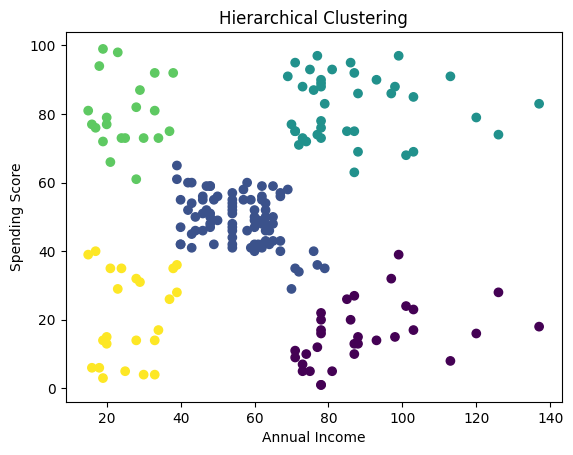

In [14]:
plt.scatter(X["Annual Income (k$)"], X["Spending Score (1-100)"], c=hc_clusters)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Hierarchical Clustering")
plt.show()

In [24]:
result = X.copy()
result["Cluster"] = clusters
result["HC_Cluster"] = hc_clusters

features = ["Annual Income (k$)", "Spending Score (1-100)"]

print("K-Means cluster profile:")
print(result.groupby("Cluster")[features].agg(['mean', 'count']))

print("\nHierarchical cluster profile:")
print(result.groupby("HC_Cluster")[features].agg(['mean', 'count']))

K-Means cluster profile:
        Annual Income (k$)       Spending Score (1-100)      
                      mean count                   mean count
Cluster                                                      
0                55.296296    81              49.518519    81
1                86.538462    39              82.128205    39
2                25.727273    22              79.363636    22
3                88.200000    35              17.114286    35
4                26.304348    23              20.913043    23

Hierarchical cluster profile:
           Annual Income (k$)       Spending Score (1-100)      
                         mean count                   mean count
HC_Cluster                                                      
0                   89.406250    32              15.593750    32
1                   55.811765    85              49.129412    85
2                   86.538462    39              82.128205    39
3                   25.095238    21              80.047619

In [25]:
income = float(input("Enter Annual Income (k$): "))
spending = float(input("Enter Spending Score (1-100): "))

data = {
    "Annual Income (k$)": income,
    "Spending Score (1-100)": spending
}

user_df = pd.DataFrame([data])

ans = kmeans.predict(user_df)

print("Predicted Cluster:", ans[0])

Enter Annual Income (k$):  90
Enter Spending Score (1-100):  20


Predicted Cluster: 3


In [26]:
segments = {
    0: "Average customers (mid income, mid spending)",
    1: "Target customers (high income, high spending)",
    2: "Impulsive buyers (low income, high spending)",
    3: "Careful spenders (high income, low spending)",
    4: "Budget customers (low income, low spending)"
}

print("Predicted Cluster:", ans[0])
print("Segment:", segments[ans[0]])

Predicted Cluster: 3
Segment: Careful spenders (high income, low spending)
